## Get the Data

Either use the provided .csv file or (optionally) get fresh (the freshest?) data from running an SQL query on StackExchange: 

Follow this link to run the query from [StackExchange](https://data.stackexchange.com/stackoverflow/query/675441/popular-programming-languages-per-over-time-eversql-com) to get your own .csv file

<code>
select dateadd(month, datediff(month, 0, q.CreationDate), 0) m, TagName, count(*)
from PostTags pt
join Posts q on q.Id=pt.PostId
join Tags t on t.Id=pt.TagId
where TagName in ('java','c','c++','python','c#','javascript','assembly','php','perl','ruby','visual basic','swift','r','object-c','scratch','go','swift','delphi')
and q.CreationDate < dateadd(month, datediff(month, 0, getdate()), 0)
group by dateadd(month, datediff(month, 0, q.CreationDate), 0), TagName
order by dateadd(month, datediff(month, 0, q.CreationDate), 0)
</code>

## Import Statements

In [102]:
import pandas as pd
import matplotlib.pyplot as plt

## Data Exploration

**Challenge**: Read the .csv file and store it in a Pandas dataframe

In [103]:
df = pd.read_csv('QueryResults.csv', names=['date', 'TagName', 'posts'], skiprows=1)

**Challenge**: Examine the first 5 rows and the last 5 rows of the of the dataframe

In [104]:
print(df.head())
print(df.tail())

                  date   TagName  posts
0  2008-07-01 00:00:00        c#      3
1  2008-08-01 00:00:00  assembly      8
2  2008-08-01 00:00:00         c     81
3  2008-08-01 00:00:00        c#    503
4  2008-08-01 00:00:00       c++    164
                     date TagName  posts
3035  2026-10-01 00:00:00     php     23
3036  2026-10-01 00:00:00  python    101
3037  2026-10-01 00:00:00       r     38
3038  2026-10-01 00:00:00    ruby      4
3039  2026-10-01 00:00:00   swift     10


**Challenge:** Check how many rows and how many columns there are. 
What are the dimensions of the dataframe?

In [105]:
df.shape

(3040, 3)

**Challenge**: Count the number of entries in each column of the dataframe

In [106]:
df.count()

date       3040
TagName    3040
posts      3040
dtype: int64

**Challenge**: Calculate the total number of post per language.
Which Programming language has had the highest total number of posts of all time?

In [107]:
data = pd.DataFrame(columns=['total_count'])
for lang in df['TagName'].unique():
    p = df[df['TagName'] == lang]
    total = p['posts'].sum()
    data.loc[lang] = total
    # data.append((lang,total))

data.sort_values(by='total_count',ascending=False)

,total_count
javascript,2521442
python,2204228
java,1914154
c#,1621620
php,1460685
c++,813974
r,510345
c,407976
swift,336087
ruby,229118


In [108]:
df.groupby('TagName').sum().sort_values('posts', ascending=False)

,date,posts
TagName,,
javascript,2008-08-01 00:00:002008-09-01 00:00:002008-10-...,2521442
python,2008-08-01 00:00:002008-09-01 00:00:002008-10-...,2204228
java,2008-08-01 00:00:002008-09-01 00:00:002008-10-...,1914154
c#,2008-07-01 00:00:002008-08-01 00:00:002008-09-...,1621620
php,2008-08-01 00:00:002008-09-01 00:00:002008-10-...,1460685
c++,2008-08-01 00:00:002008-09-01 00:00:002008-10-...,813974
r,2008-09-01 00:00:002008-11-01 00:00:002008-12-...,510345
c,2008-08-01 00:00:002008-09-01 00:00:002008-10-...,407976
swift,2009-01-01 00:00:002009-02-01 00:00:002009-03-...,336087


Some languages are older (e.g., C) and other languages are newer (e.g., Swift). The dataset starts in September 2008.

**Challenge**: How many months of data exist per language? Which language had the fewest months with an entry? 


In [109]:
df.groupby('TagName').count()

,date,posts
TagName,,
assembly,219,219
c,219,219
c#,220,220
c++,219,219
delphi,219,219
go,204,204
java,219,219
javascript,219,219
perl,218,218


## Data Cleaning

Let's fix the date format to make it more readable. We need to use Pandas to change format from a string of "2008-07-01 00:00:00" to a datetime object with the format of "2008-07-01"

In [110]:
# df['m'] = df['m'].apply(lambda x:x.split(' ')[0])

In [112]:
df.date = pd.to_datetime(df.date)
df.head()

,date,TagName,posts
0,2008-07-01,c#,3
1,2008-08-01,assembly,8
2,2008-08-01,c,81
3,2008-08-01,c#,503
4,2008-08-01,c++,164


## Data Manipulation



**Challenge**: What are the dimensions of our new dataframe? How many rows and columns does it have? Print out the column names and print out the first 5 rows of the dataframe.

In [113]:
df.shape

(3040, 3)

In [115]:
df.columns

Index(['date', 'TagName', 'posts'], dtype='object')

In [114]:
df.head()

,date,TagName,posts
0,2008-07-01,c#,3
1,2008-08-01,assembly,8
2,2008-08-01,c,81
3,2008-08-01,c#,503
4,2008-08-01,c++,164


**Challenge**: Count the number of entries per programming language. Why might the number of entries be different? 

In [116]:
df.groupby('TagName').count()

,date,posts
TagName,,
assembly,219,219
c,219,219
c#,220,220
c++,219,219
delphi,219,219
go,204,204
java,219,219
javascript,219,219
perl,218,218


In [118]:
reshaped_df = df.pivot(index='date', columns='TagName', values='posts')
reshaped_df

TagName,assembly,c,c#,c++,delphi,go,java,javascript,perl,php,python,r,ruby,swift
date,,,,,,,,,,,,,,
2008-07-01,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-08-01,8.0,81.0,503.0,164.0,13.0,NaN,220.0,160.0,28.0,157.0,119.0,NaN,68.0,NaN
2008-09-01,28.0,320.0,1636.0,749.0,104.0,NaN,1119.0,629.0,128.0,471.0,533.0,6.0,285.0,NaN
2008-10-01,16.0,302.0,1982.0,804.0,112.0,NaN,1142.0,721.0,128.0,603.0,504.0,NaN,245.0,NaN
2008-11-01,16.0,257.0,1727.0,733.0,139.0,NaN,951.0,581.0,97.0,497.0,446.0,1.0,154.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-06-01,7.0,62.0,99.0,99.0,11.0,6.0,79.0,94.0,6.0,28.0,210.0,40.0,2.0,30.0
2026-07-01,4.0,39.0,66.0,95.0,4.0,4.0,68.0,69.0,5.0,23.0,134.0,54.0,2.0,15.0
2026-08-01,4.0,38.0,50.0,89.0,3.0,4.0,64.0,68.0,NaN,18.0,139.0,25.0,2.0,17.0


In [119]:
reshaped_df.shape

(220, 14)

In [120]:
reshaped_df.head()

TagName,assembly,c,c#,c++,delphi,go,java,javascript,perl,php,python,r,ruby,swift
date,,,,,,,,,,,,,,
2008-07-01,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-08-01,8.0,81.0,503.0,164.0,13.0,NaN,220.0,160.0,28.0,157.0,119.0,NaN,68.0,NaN
2008-09-01,28.0,320.0,1636.0,749.0,104.0,NaN,1119.0,629.0,128.0,471.0,533.0,6.0,285.0,NaN
2008-10-01,16.0,302.0,1982.0,804.0,112.0,NaN,1142.0,721.0,128.0,603.0,504.0,NaN,245.0,NaN
2008-11-01,16.0,257.0,1727.0,733.0,139.0,NaN,951.0,581.0,97.0,497.0,446.0,1.0,154.0,NaN


In [121]:
reshaped_df.tail()

TagName,assembly,c,c#,c++,delphi,go,java,javascript,perl,php,python,r,ruby,swift
date,,,,,,,,,,,,,,
2026-06-01,7.0,62.0,99.0,99.0,11.0,6.0,79.0,94.0,6.0,28.0,210.0,40.0,2.0,30.0
2026-07-01,4.0,39.0,66.0,95.0,4.0,4.0,68.0,69.0,5.0,23.0,134.0,54.0,2.0,15.0
2026-08-01,4.0,38.0,50.0,89.0,3.0,4.0,64.0,68.0,NaN,18.0,139.0,25.0,2.0,17.0
2026-09-01,5.0,44.0,52.0,83.0,5.0,7.0,39.0,54.0,3.0,14.0,109.0,30.0,4.0,15.0
2026-10-01,11.0,43.0,50.0,79.0,3.0,2.0,38.0,52.0,3.0,23.0,101.0,38.0,4.0,10.0


In [122]:
reshaped_df.columns

Index(['assembly', 'c', 'c#', 'c++', 'delphi', 'go', 'java', 'javascript',
       'perl', 'php', 'python', 'r', 'ruby', 'swift'],
      dtype='object', name='TagName')

In [123]:
reshaped_df.count()

TagName
assembly      219
c             219
c#            220
c++           219
delphi        219
go            204
java          219
javascript    219
perl          218
php           219
python        219
r             217
ruby          219
swift         210
dtype: int64

In [124]:
reshaped_df.fillna(0, inplace=True)

In [125]:
reshaped_df.head()

TagName,assembly,c,c#,c++,delphi,go,java,javascript,perl,php,python,r,ruby,swift
date,,,,,,,,,,,,,,
2008-07-01,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2008-08-01,8.0,81.0,503.0,164.0,13.0,0.0,220.0,160.0,28.0,157.0,119.0,0.0,68.0,0.0
2008-09-01,28.0,320.0,1636.0,749.0,104.0,0.0,1119.0,629.0,128.0,471.0,533.0,6.0,285.0,0.0
2008-10-01,16.0,302.0,1982.0,804.0,112.0,0.0,1142.0,721.0,128.0,603.0,504.0,0.0,245.0,0.0
2008-11-01,16.0,257.0,1727.0,733.0,139.0,0.0,951.0,581.0,97.0,497.0,446.0,1.0,154.0,0.0


In [126]:
reshaped_df.isna().values.any()


np.False_

In [131]:
reshaped_df.sum()

TagName
assembly        45063.0
c              407976.0
c#            1621620.0
c++            813974.0
delphi          52548.0
go              74449.0
java          1914154.0
javascript    2521442.0
perl            68295.0
php           1460685.0
python        2204228.0
r              510345.0
ruby           229118.0
swift          336087.0
dtype: float64

## Data Visualisaton with with Matplotlib


**Challenge**: Use the [matplotlib documentation](https://matplotlib.org/3.2.1/api/_as_gen/matplotlib.pyplot.plot.html#matplotlib.pyplot.plot) to plot a single programming language (e.g., java) on a chart.

In [138]:
reshaped_df.loc[:,'java']

date
2008-07-01       0.0
2008-08-01     220.0
2008-09-01    1119.0
2008-10-01    1142.0
2008-11-01     951.0
               ...  
2026-06-01      79.0
2026-07-01      68.0
2026-08-01      64.0
2026-09-01      39.0
2026-10-01      38.0
Name: java, Length: 220, dtype: float64

(0.0, 35000.0)

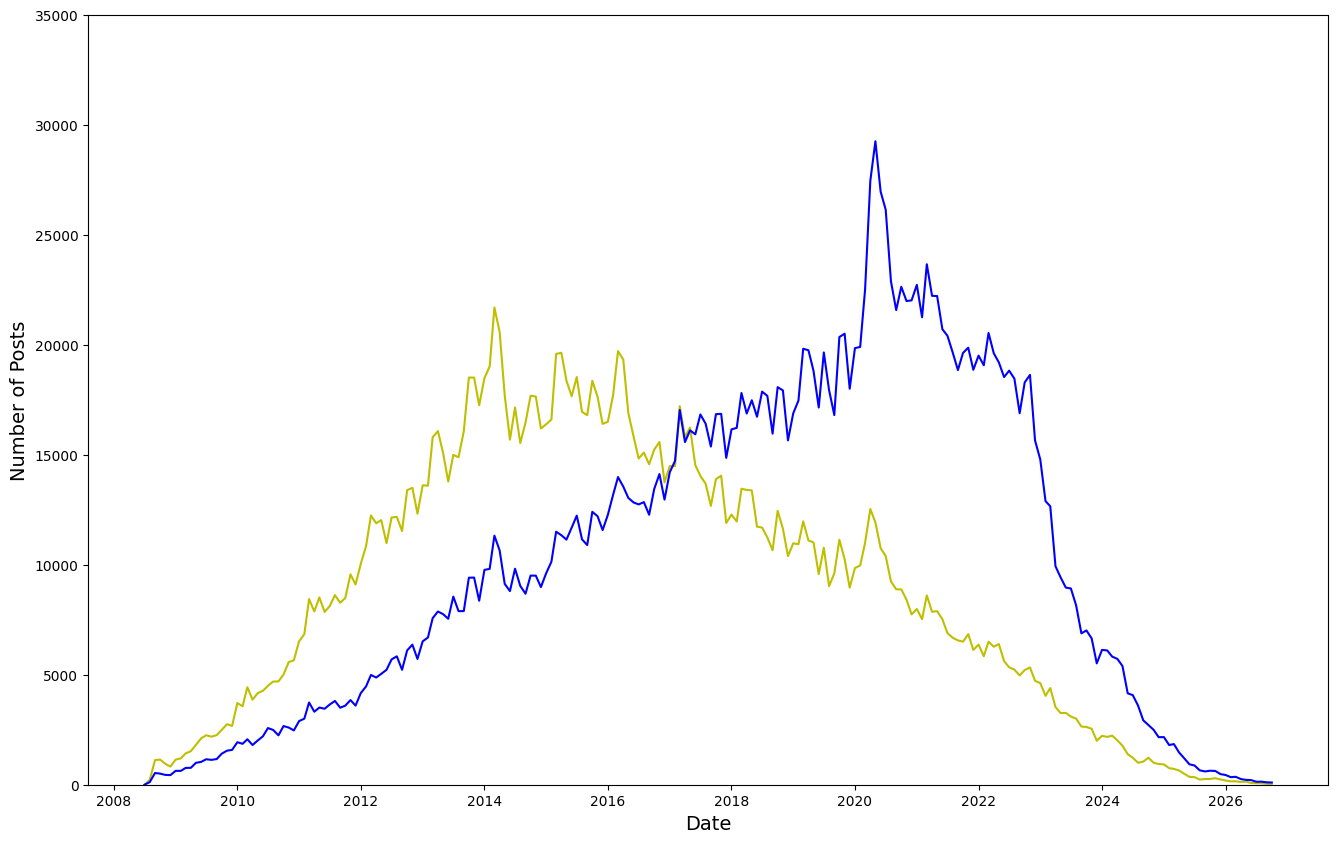

In [147]:
plt.figure(figsize=(16,10)) 
plt.plot(reshaped_df.loc[:,'java'], c='y')
plt.plot(reshaped_df.loc[:,'python'], c='b')
plt.xlabel('Date', fontsize=14)
plt.ylabel('Number of Posts', fontsize=14)
plt.ylim(0, 35000)


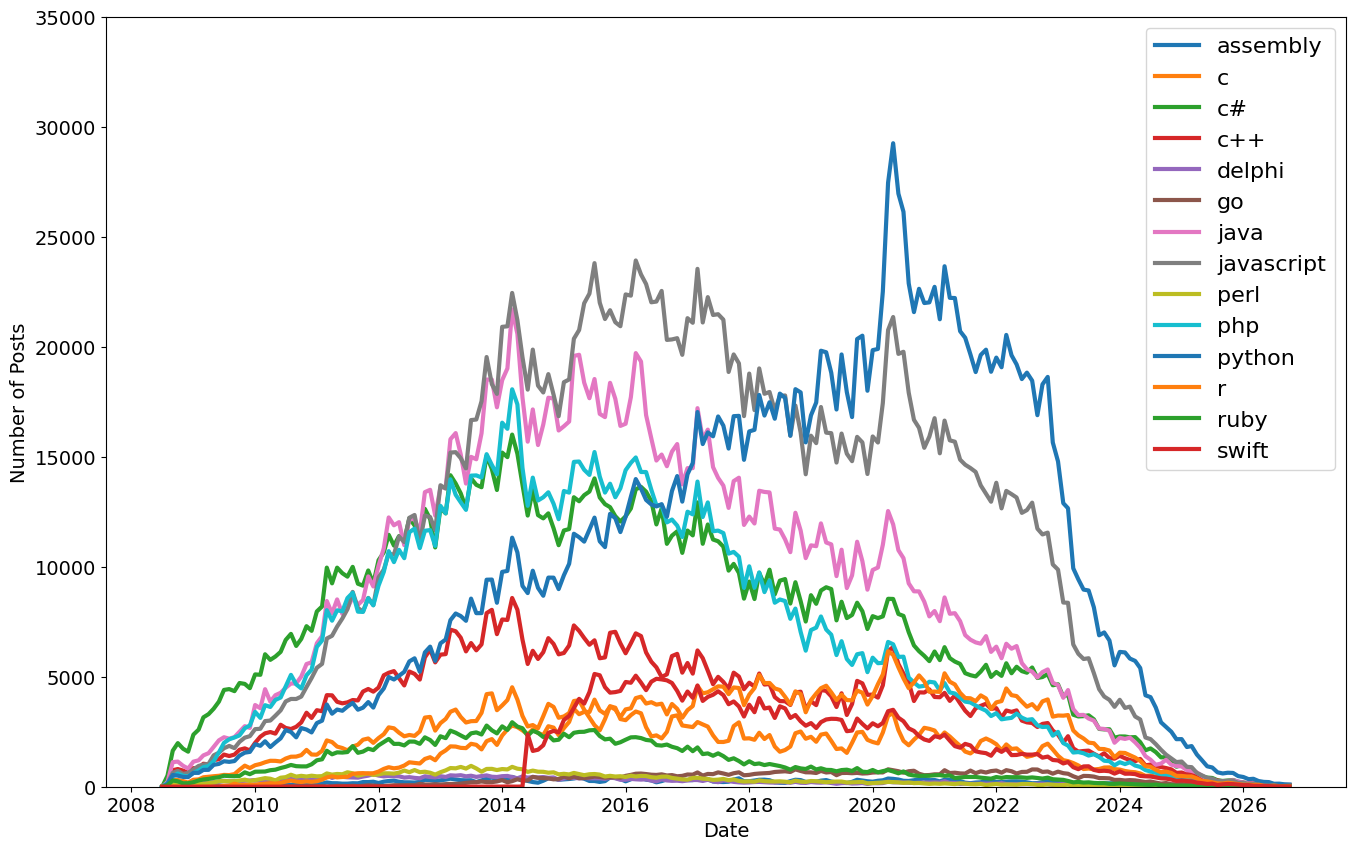

In [151]:
plt.figure(figsize=(16,10))
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Number of Posts', fontsize=14)
plt.ylim(0, 35000)
 
for column in reshaped_df.columns:
    plt.plot(reshaped_df.index, reshaped_df[column], 
             linewidth=3, label=reshaped_df[column].name)
 
plt.legend(fontsize=16) 

**Challenge**: Show two line (e.g. for Java and Python) on the same chart.

# Smoothing out Time Series Data

Time series data can be quite noisy, with a lot of up and down spikes. To better see a trend we can plot an average of, say 6 or 12 observations. This is called the rolling mean. We calculate the average in a window of time and move it forward by one overservation. Pandas has two handy methods already built in to work this out: [rolling()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.rolling.html) and [mean()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.core.window.rolling.Rolling.mean.html). 

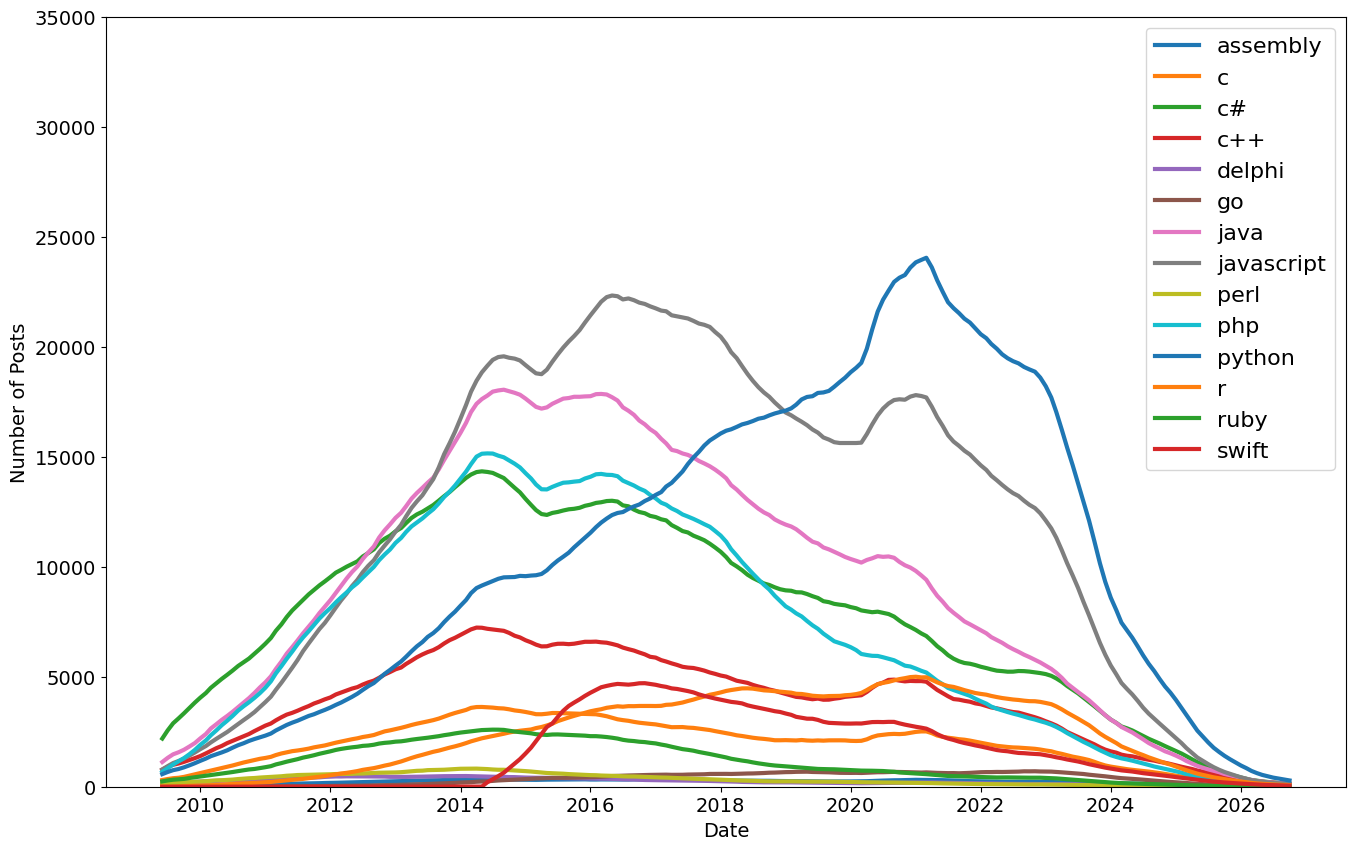

In [154]:
# The window is number of observations that are averaged
roll_df = reshaped_df.rolling(window=12).mean()
 
plt.figure(figsize=(16,10))
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Number of Posts', fontsize=14)
plt.ylim(0, 35000)
 
# plot the roll_df instead
for column in roll_df.columns:
    plt.plot(roll_df.index, roll_df[column], 
             linewidth=3, label=roll_df[column].name)
 
plt.legend(fontsize=16)